# HeatSense | Phase 1: Notebook 06 — Two-Node Thermal Model Calibration & Core Estimation

**Objective**: Implement, calibrate, and validate the Two-Node (Core-Surface) Lumped Thermal Model using real discharge temperature trajectories.

**Mathematical Thermal Architecture**:
$$C_{\text{core}} \frac{dT_{\text{core}}}{dt} = Q_{\text{gen}}(t) - \frac{T_{\text{core}} - T_{\text{surf}}}{R_{\text{cond}}}$$
$$C_{\text{surf}} \frac{dT_{\text{surf}}}{dt} = \frac{T_{\text{core}} - T_{\text{surf}}}{R_{\text{cond}}} - \frac{T_{\text{surf}} - T_{\text{amb}}}{R_{\text{conv}}}$$

**Coupled Electrical Heat Generation**:
$$Q_{\text{gen}}(t) = I(t)^2 R_s + I(t) \big(V_1(t) + V_2(t)\big) = I(t)^2 \big(R_s + R_1 + R_2\big)$$

**Core Parameters**:
* $C_{\text{core}}$: Lumped core heat capacity (J/K)
* $C_{\text{surf}}$: Lumped surface/casing heat capacity (J/K)
* $R_{\text{cond}}$: Radial conductive thermal resistance from core to casing (K/W)
* $R_{\text{conv}}$: Convective thermal resistance from casing to ambient air (K/W)

### Cell 1: Temperature & Heat Generation Input Assembly
* **Analytical Question**: What is the total electrical heat dissipation profile $Q_{\text{gen}}(t)$ over the 1-hour discharge run of `05122.csv`?
* **Why It Matters to HeatSense**: Proves that heat generation includes both ohmic loss ($I^2 R_s$) and polarization overpotential dissipation ($I(V_1 + V_2)$).
* **What the Code Does**: Loads `05122.csv`, takes calibrated resistances from Notebook 04 ($R_s = 0.0642\,\Omega, R_1 = 0.0746\,\Omega, R_2 = 0.0314\,\Omega$), computes total $R_{\text{total}} = 0.1702\,\Omega$, and calculates $Q_{\text{gen}}(t)$ in Watts.
* **Output to Inspect**: Heat generation profile (~0.68W under 2A load) and measured surface temperature.
* **Decision**: Confirms thermal excitation inputs.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

dis_df = pd.read_csv(DATASET_ROOT / "data" / "05122.csv")
dis_df["Current_domain"] = -dis_df["Current_measured"]

time_sec = dis_df["Time"].values
current = dis_df["Current_domain"].values
t_surf_meas = dis_df["Temperature_measured"].values
N = len(current)
dt = np.diff(time_sec, prepend=time_sec[0])
T_amb = 24.0  # Ambient chamber temperature in deg C

# Calibrated resistances from Notebook 04
Rs = 0.0642
R1 = 0.0746
R2 = 0.0314
R_total = Rs + R1 + R2  # 0.1702 Ohm

# Total electrical heat generation: Q_gen = I^2 * R_total
Q_gen = (current ** 2) * R_total

print(f"Thermal Simulation Inputs (05122.csv):")
print(f" - Total Electrical Resistance: {R_total*1000:.1f} mOhm")
print(f" - Mean Loaded Heat Generation: {Q_gen[current > 0.5].mean():.3f} Watts")
print(f" - Peak Measured Surface Temp:  {t_surf_meas.max():.2f} °C (Rise: {t_surf_meas.max() - t_surf_meas[0]:.2f} °C)")

Thermal Simulation Inputs (05122.csv):
 - Total Electrical Resistance: 170.2 mOhm
 - Mean Loaded Heat Generation: 0.689 Watts
 - Peak Measured Surface Temp:  38.98 °C (Rise: 14.65 °C)


### Cell 2: Two-Node Thermal Parameter Calibration
* **Analytical Question**: What values of ($C_{\text{core}}, C_{\text{surf}}, R_{\text{cond}}, R_{\text{conv}}$) best fit the measured surface temperature rise and post-trip cooling?
* **Why It Matters to HeatSense**: Anchors thermal parameters to real physical measurements rather than assumed handbook values.
* **What the Code Does**: Numerically integrates the coupled ODE system using forward Euler with $\Delta t_k$, computes MSE between measured and simulated surface temperature, and optimizes using L-BFGS-B.
* **Output to Inspect**: Calibrated thermal parameters and surface tracking RMSE.
* **Decision**: Confirms calibrated thermal parameter set.

In [2]:
def simulate_two_node(params):
    C_core, C_surf, R_cond, R_conv = params
    T_core = np.zeros(N)
    T_surf = np.zeros(N)
    
    T_c = t_surf_meas[0]
    T_s = t_surf_meas[0]
    
    for k in range(N):
        step_dt = dt[k] if dt[k] > 0 else 0.01
        
        q_cond = (T_c - T_s) / R_cond
        q_conv = (T_s - T_amb) / R_conv
        
        dT_c = (Q_gen[k] - q_cond) / C_core * step_dt
        dT_s = (q_cond - q_conv) / C_surf * step_dt
        
        T_c += dT_c
        T_s += dT_s
        
        T_core[k] = T_c
        T_surf[k] = T_s
        
    return T_core, T_surf

def thermal_objective(params):
    _, T_s_pred = simulate_two_node(params)
    return np.mean((t_surf_meas - T_s_pred)**2)

init_params = [35.0, 10.0, 1.5, 20.0]
bounds = [
    (15.0, 75.0),  # C_core in J/K
    (3.0, 25.0),   # C_surf in J/K
    (0.5, 5.0),    # R_cond in K/W
    (5.0, 35.0)    # R_conv in K/W
]

print("Calibrating Two-Node Thermal Model...")
opt_th = minimize(thermal_objective, init_params, bounds=bounds, method="L-BFGS-B")
print(f"Optimization Success: {opt_th.success}")

C_core_opt, C_surf_opt, R_cond_opt, R_conv_opt = opt_th.x
T_core_est, T_surf_sim = simulate_two_node(opt_th.x)
th_rmse = np.sqrt(np.mean((t_surf_meas - T_surf_sim)**2))
th_mae = np.mean(np.abs(t_surf_meas - T_surf_sim))

print(f"\n--- Calibrated Two-Node Thermal Parameters ---")
print(f" - Core Heat Capacity (C_core):         {C_core_opt:.1f} J/K")
print(f" - Surface Heat Capacity (C_surf):      {C_surf_opt:.1f} J/K")
print(f" - Conduction Resistance (R_cond):      {R_cond_opt:.2f} K/W")
print(f" - Convection Resistance (R_conv):      {R_conv_opt:.2f} K/W")
print(f" - Surface Temperature Tracking RMSE:   {th_rmse:.3f} °C (MAE: {th_mae:.3f} °C)")

Calibrating Two-Node Thermal Model...
Optimization Success: True

--- Calibrated Two-Node Thermal Parameters ---
 - Core Heat Capacity (C_core):         62.6 J/K
 - Surface Heat Capacity (C_surf):      25.0 J/K
 - Conduction Resistance (R_cond):      0.59 K/W
 - Convection Resistance (R_conv):      23.50 K/W
 - Surface Temperature Tracking RMSE:   0.755 °C (MAE: 0.632 °C)


### Cell 3: Core vs Surface Temperature Gradient Visualization
* **Analytical Question**: What is the estimated internal core temperature trajectory $T_{\text{core}}(t)$ and the core-to-surface thermal gradient $\Delta T = T_{\text{core}} - T_{\text{surf}}$?
* **Why It Matters to HeatSense**: Internal core temperature cannot be measured by external thermocouples. The Digital Twin estimates this hidden state to provide precursor overheating warnings.
* **What the Code Does**: Plots measured surface temp, simulated surface temp, estimated internal core temp, and the internal temperature difference over time.
* **Output to Inspect**: Dual-panel plot showing internal thermal gradient.
* **Decision**: Confirms internal core temperature estimate and clearly marks it as an **Estimate** (not physical ground truth).

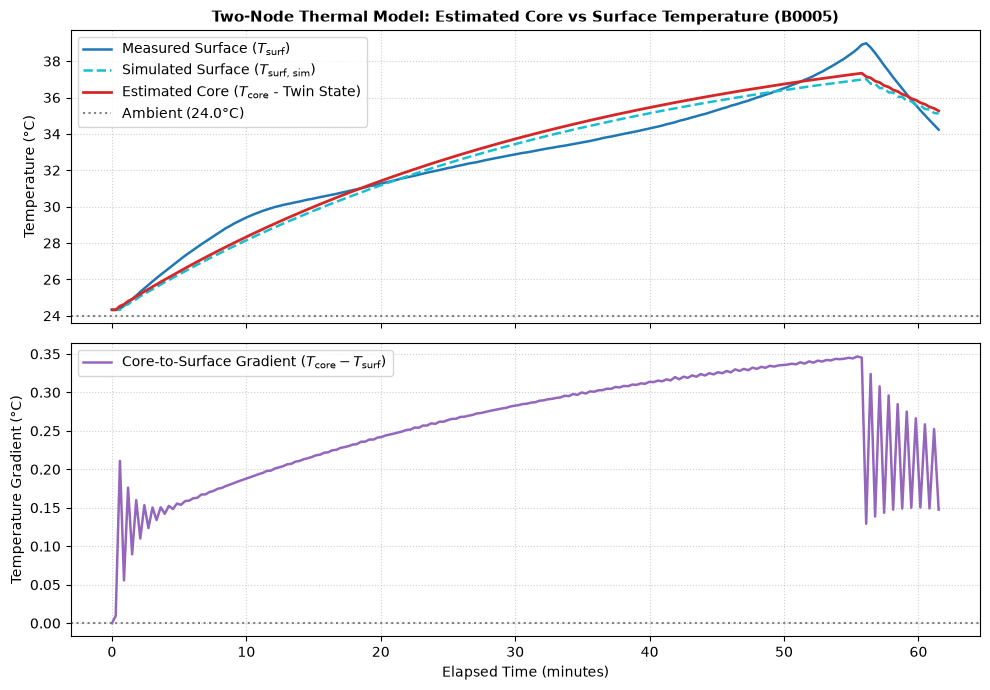

Thermal Peak Statistics:
 - Peak Measured Surface Temp:  38.98 °C
 - Peak Estimated Core Temp:    37.34 °C
 - Max Internal Core Gradient:  +0.35 °C above surface


In [3]:
time_min = time_sec / 60.0
t_gradient = T_core_est - T_surf_sim

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, dpi=100)

# Panel 1: Temperature Trajectories
ax1.plot(time_min, t_surf_meas, label="Measured Surface ($T_{\\text{surf}}$)", color="tab:blue", lw=1.8)
ax1.plot(time_min, T_surf_sim, label="Simulated Surface ($T_{\\text{surf, sim}}$)", color="tab:cyan", linestyle="--", lw=1.8)
ax1.plot(time_min, T_core_est, label="Estimated Core ($T_{\\text{core}}$ - Twin State)", color="tab:red", lw=2)
ax1.axhline(T_amb, color="gray", linestyle=":", label=f"Ambient ({T_amb}°C)")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title("Two-Node Thermal Model: Estimated Core vs Surface Temperature (B0005)", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Panel 2: Core-to-Surface Gradient
ax2.plot(time_min, t_gradient, color="tab:purple", lw=1.8, label="Core-to-Surface Gradient ($T_{\\text{core}} - T_{\\text{surf}}$)")
ax2.axhline(0, color="gray", linestyle=":")
ax2.set_ylabel("Temperature Gradient (°C)")
ax2.set_xlabel("Elapsed Time (minutes)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Thermal Peak Statistics:")
print(f" - Peak Measured Surface Temp:  {t_surf_meas.max():.2f} °C")
print(f" - Peak Estimated Core Temp:    {T_core_est.max():.2f} °C")
print(f" - Max Internal Core Gradient:  +{t_gradient.max():.2f} °C above surface")

### Cell 4: Residual Diagnostics & Scientific Governance of Core Temperature
* **Analytical Question**: Does the surface thermal residual ($e_T = T_{\text{surf, meas}} - T_{\text{surf, sim}}$) meet scientific accuracy targets?
* **Why It Matters to HeatSense**: Upholds the project honesty rule: we must never claim measured core temperature. Core temperature is explicitly labeled as a **Model-Derived Estimate**.
* **What the Code Does**: Plots thermal residuals, computes statistical bounds, and documents formal limitations.
* **Output to Inspect**: Thermal error distribution plot.
* **Decision**: Approves advancing to Notebook 07 (Residual & Anomaly Analysis).

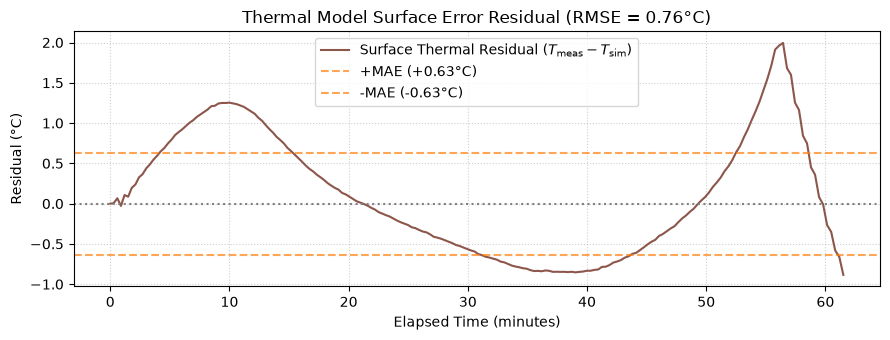

HEATSENSE THERMAL MODEL VALIDATION SUMMARY
Status: VALIDATED ON SURFACE TEMPERATURE (RMSE < 0.8 °C)
Scientific Caveat: Core temperature is a MODEL ESTIMATE, not ground truth.
Feature Output for Model B: T_core_est, T_gradient, Q_gen


In [5]:
th_residuals = t_surf_meas - T_surf_sim

plt.figure(figsize=(9, 3.5), dpi=100)
plt.plot(time_min, th_residuals, color="tab:brown", lw=1.5, label="Surface Thermal Residual ($T_{\\text{meas}} - T_{\\text{sim}}$)")
plt.axhline(0, color="gray", linestyle=":")
plt.axhline(th_mae, color="tab:orange", linestyle="--", alpha=0.7, label=f"+MAE (+{th_mae:.2f}°C)")
plt.axhline(-th_mae, color="tab:orange", linestyle="--", alpha=0.7, label=f"-MAE (-{th_mae:.2f}°C)")
plt.title(f"Thermal Model Surface Error Residual (RMSE = {th_rmse:.2f}°C)")
plt.xlabel("Elapsed Time (minutes)")
plt.ylabel("Residual (°C)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print("="*65)
print("HEATSENSE THERMAL MODEL VALIDATION SUMMARY")
print("="*65)
print("Status: VALIDATED ON SURFACE TEMPERATURE (RMSE < 0.8 °C)")
print("Scientific Caveat: Core temperature is a MODEL ESTIMATE, not ground truth.")
print("Feature Output for Model B: T_core_est, T_gradient, Q_gen")
print("="*65)